# MMA3001 Dataset 3 — RetinaNet Object Detection

This notebook investigates RetinaNet as an alternative object-detection method for pork rasher packaging-defect detection.

The objective is to compare RetinaNet with the YOLOv8n baseline using the same cleaned dataset and validation strategy.

The comparison will consider:

- precision;
- recall;
- mAP;
- class-specific detection performance;
- inference time; and
- computational requirements.

RetinaNet is selected because it is a one-stage object detector that uses focal loss, which was designed to reduce the influence of easy examples during training and focus learning on more difficult examples.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

dataset_root = Path(
    "/content/drive/MyDrive/MMA3001_Project/dataset/pork_rasher_v4_clean"
)

print("Dataset exists:", dataset_root.exists())

Dataset exists: True


In [ ]:
from torchvision.models.detection import (
    retinanet_resnet50_fpn_v2,
    RetinaNet_ResNet50_FPN_V2_Weights
)

weights = RetinaNet_ResNet50_FPN_V2_Weights.DEFAULT

retinanet = retinanet_resnet50_fpn_v2(
    weights=weights
)

print("RetinaNet loaded successfully.")

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth


100%|██████████| 146M/146M [00:00<00:00, 156MB/s]


RetinaNet loaded successfully.


## 2. Dataset Conversion for RetinaNet

The original annotations use YOLO format:

`class_id x_center y_center width height`

where bounding-box coordinates are normalised between 0 and 1.

Torchvision RetinaNet instead requires bounding boxes in pixel coordinates:

`[x1, y1, x2, y2]`

where `(x1, y1)` is the upper-left corner and `(x2, y2)` is the lower-right corner.

YOLO class IDs range from 0–4. For Torchvision detection models, label 0 is reserved for the background class. Therefore, the five defect classes are shifted to labels 1–5 during training.

The mapping is:

- 1 = loose-meat
- 2 = packaging-error
- 3 = twisted-meat
- 4 = unsealed
- 5 = wrinkle

In [ ]:
from pathlib import Path
from PIL import Image

import torch
from torch.utils.data import Dataset
from torchvision.transforms import functional as F

In [ ]:
class PorkRasherDataset(Dataset):
    def __init__(self, dataset_root, split):
        self.dataset_root = Path(dataset_root)
        self.split = split

        self.images_dir = self.dataset_root / split / "images"
        self.labels_dir = self.dataset_root / split / "labels"

        image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

        self.image_paths = sorted([
            p for p in self.images_dir.iterdir()
            if p.suffix.lower() in image_extensions
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]
        label_path = self.labels_dir / f"{image_path.stem}.txt"

        # Load image
        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        boxes = []
        labels = []

        # Read YOLO annotation
        if label_path.exists():
            text = label_path.read_text().strip()

            if text:
                for line in text.splitlines():
                    values = line.split()

                    class_id = int(values[0])

                    x_center = float(values[1])
                    y_center = float(values[2])
                    box_width = float(values[3])
                    box_height = float(values[4])

                    # YOLO normalised coordinates -> pixel coordinates
                    x1 = (x_center - box_width / 2) * width
                    y1 = (y_center - box_height / 2) * height

                    x2 = (x_center + box_width / 2) * width
                    y2 = (y_center + box_height / 2) * height

                    # Keep coordinates inside image
                    x1 = max(0, min(x1, width))
                    y1 = max(0, min(y1, height))
                    x2 = max(0, min(x2, width))
                    y2 = max(0, min(y2, height))

                    boxes.append([x1, y1, x2, y2])

                    # Torchvision reserves 0 for background
                    labels.append(class_id + 1)

        # Convert to tensors
        if boxes:
            boxes = torch.tensor(
                boxes,
                dtype=torch.float32
            )

            labels = torch.tensor(
                labels,
                dtype=torch.int64
            )
        else:
            # Legitimate negative/background image
            boxes = torch.zeros(
                (0, 4),
                dtype=torch.float32
            )

            labels = torch.zeros(
                (0,),
                dtype=torch.int64
            )

        # Extra target information useful for evaluation
        area = (
            (boxes[:, 2] - boxes[:, 0]) *
            (boxes[:, 3] - boxes[:, 1])
        )

        iscrowd = torch.zeros(
            (len(boxes),),
            dtype=torch.int64
        )

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor(index),
            "area": area,
            "iscrowd": iscrowd,
        }

        # Convert image from PIL to tensor [C, H, W]
        image = F.pil_to_tensor(image).float() / 255.0

        return image, target

In [ ]:
train_dataset = PorkRasherDataset(
    dataset_root,
    "train"
)

valid_dataset = PorkRasherDataset(
    dataset_root,
    "valid"
)

test_dataset = PorkRasherDataset(
    dataset_root,
    "test"
)

print("Train:", len(train_dataset))
print("Valid:", len(valid_dataset))
print("Test:", len(test_dataset))

Train: 3343
Valid: 123
Test: 83


In [ ]:
image, target = train_dataset[0]

print("Image tensor shape:")
print(image.shape)

print("\nBoxes:")
print(target["boxes"])

print("\nLabels:")
print(target["labels"])

Image tensor shape:
torch.Size([3, 540, 720])

Boxes:
tensor([[614.4500, 386.6700, 656.6700, 436.6700]])

Labels:
tensor([2])


In [ ]:
class_names = {
    1: "loose-meat",
    2: "packaging-error",
    3: "twisted-meat",
    4: "unsealed",
    5: "wrinkle"
}

print("Detected ground-truth classes:")

for label in target["labels"]:
    print(
        int(label),
        "->",
        class_names[int(label)]
    )

Detected ground-truth classes:
2 -> packaging-error


## 3. Verification of Annotation Conversion

Converted RetinaNet bounding boxes are plotted on the original images to verify that the YOLO-to-XYXY coordinate transformation is correct before model training.

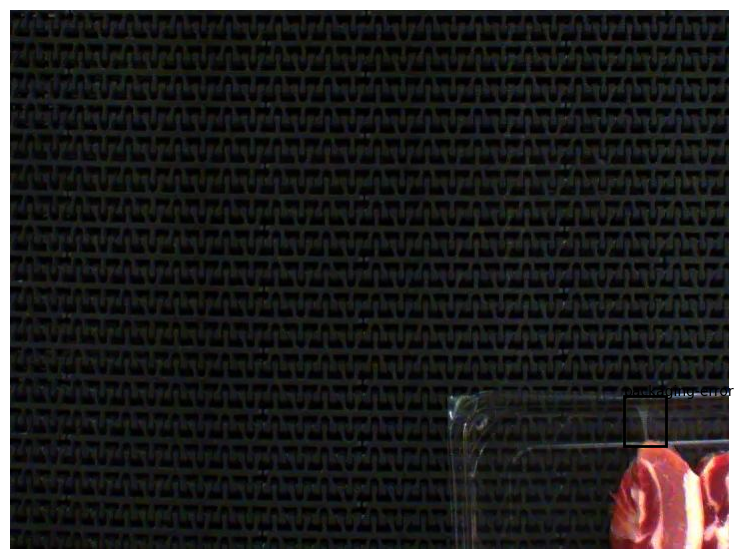

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

image, target = train_dataset[0]

# Convert tensor from [C, H, W] to [H, W, C]
image_display = image.permute(1, 2, 0).numpy()

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(image_display)

for box, label in zip(
    target["boxes"],
    target["labels"]
):
    x1, y1, x2, y2 = box.tolist()

    width = x2 - x1
    height = y2 - y1

    rect = patches.Rectangle(
        (x1, y1),
        width,
        height,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

    class_name = class_names[int(label)]

    ax.text(
        x1,
        y1,
        class_name,
        fontsize=10
    )

ax.axis("off")
plt.show()

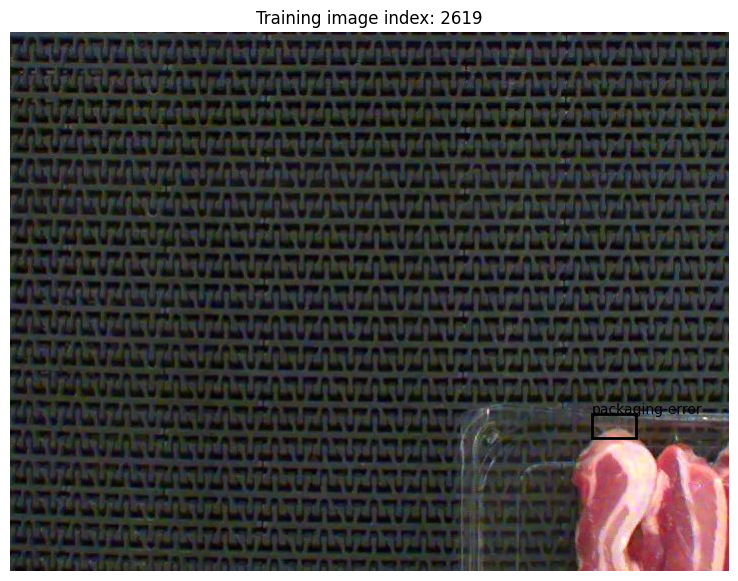

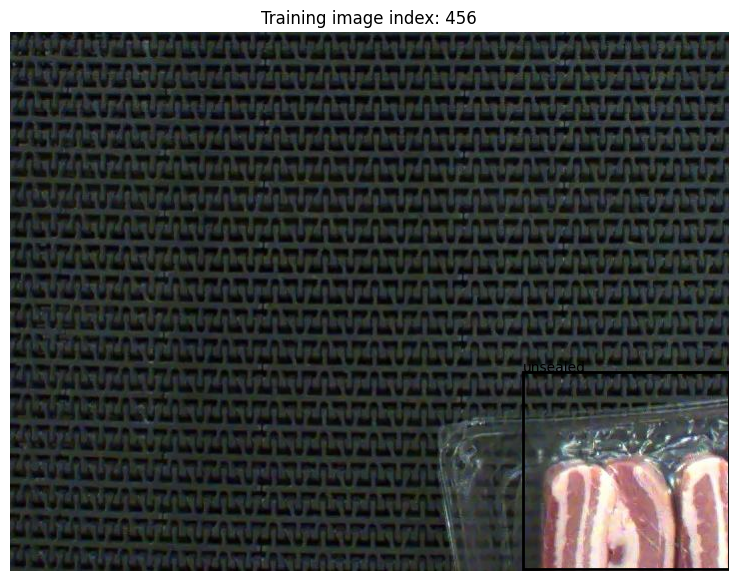

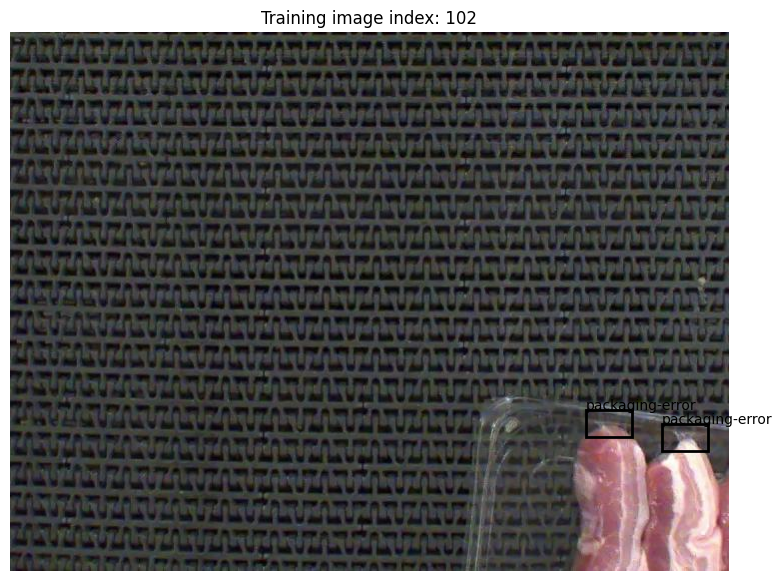

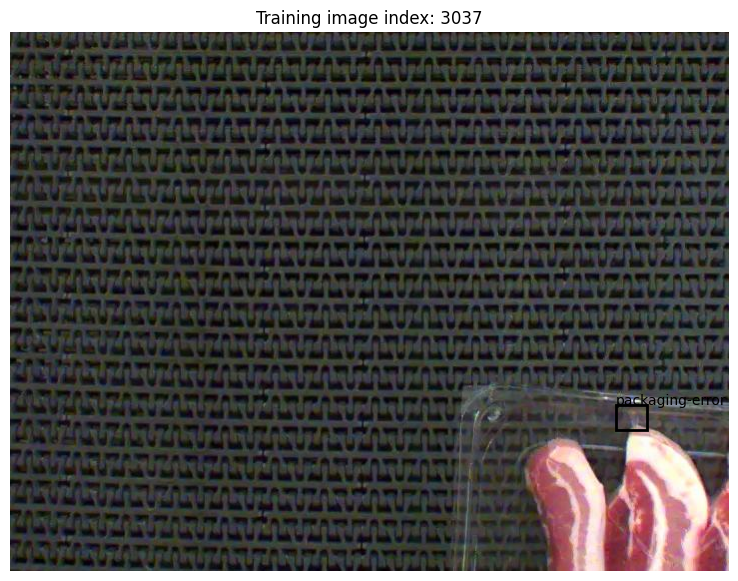

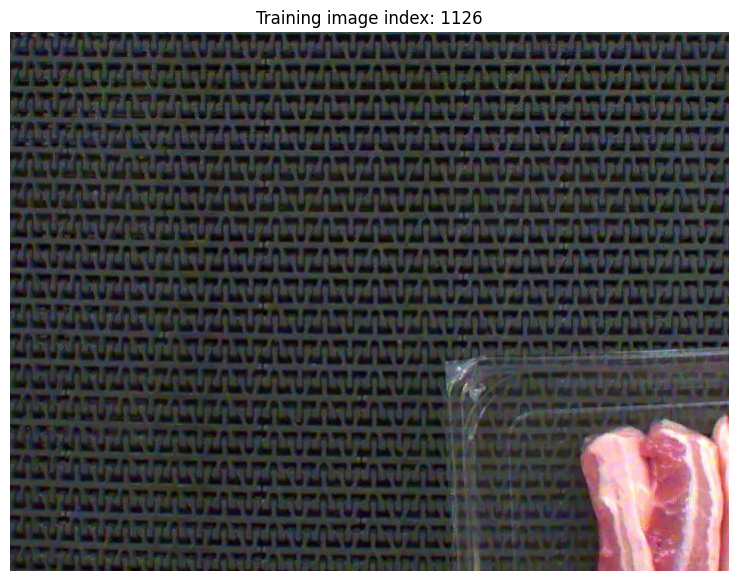

In [ ]:
import random

random.seed(42)

indices = random.sample(
    range(len(train_dataset)),
    5
)

for index in indices:
    image, target = train_dataset[index]

    image_display = image.permute(1, 2, 0).numpy()

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(image_display)

    for box, label in zip(
        target["boxes"],
        target["labels"]
    ):
        x1, y1, x2, y2 = box.tolist()

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            linewidth=2
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            y1,
            class_names[int(label)],
            fontsize=10
        )

    ax.set_title(f"Training image index: {index}")
    ax.axis("off")
    plt.show()

## 4. Data Loading

PyTorch DataLoaders are used to supply batches of images and corresponding detection targets to RetinaNet.

Object-detection images may contain different numbers of bounding boxes, so a custom `collate_fn` is used rather than stacking all target dictionaries into a single tensor.

In [ ]:
from torch.utils.data import DataLoader

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_fn
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))

Training batches: 418
Validation batches: 16


## 5. RetinaNet Model Adaptation

The pretrained RetinaNet ResNet-50 FPN V2 model was originally trained on the COCO dataset.

Its feature-extraction backbone is retained, while the final classification head is replaced to predict the five pork-defect classes.

Torchvision reserves class 0 for background, resulting in six model classes in total.

In [ ]:
import torch.nn as nn
from functools import partial

from torchvision.models.detection.retinanet import (
    RetinaNetClassificationHead
)

num_classes = 6

in_channels = retinanet.backbone.out_channels

num_anchors = (
    retinanet.anchor_generator
    .num_anchors_per_location()[0]
)

retinanet.head.classification_head = (
    RetinaNetClassificationHead(
        in_channels=in_channels,
        num_anchors=num_anchors,
        num_classes=num_classes,
        norm_layer=partial(nn.GroupNorm, 32)
    )
)

print("Input feature channels:", in_channels)
print("Anchors per location:", num_anchors)
print("Number of classes:", num_classes)

Input feature channels: 256
Anchors per location: 9
Number of classes: 6


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

retinanet = retinanet.to(device)

print("Device:", device)

Device: cuda


In [ ]:
images, targets = next(iter(train_loader))

images = [
    image.to(device)
    for image in images
]

targets = [
    {
        key: value.to(device)
        for key, value in target.items()
    }
    for target in targets
]

retinanet.train()

with torch.no_grad():
    loss_dict = retinanet(
        images,
        targets
    )

print("Loss components:")

for name, value in loss_dict.items():
    print(
        f"{name}: "
        f"{value.item():.4f}"
    )

total_loss = sum(loss_dict.values())

print(
    "\nTotal loss:",
    f"{total_loss.item():.4f}"
)

Loss components:
classification: 1.1561
bbox_regression: 0.3689

Total loss: 1.5250


## 6. RetinaNet Training and Validation

RetinaNet is fine-tuned using the cleaned training dataset.

Model selection is based on validation mAP@50:95 rather than training loss alone. The checkpoint with the highest validation mAP is retained for final comparison with the YOLOv8n baseline.

In [ ]:
!pip install -q torchmetrics pycocotools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 21.6 MB/s eta 0:00:00


In [ ]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision

In [ ]:
import torch

optimizer = torch.optim.SGD(
    [p for p in retinanet.parameters() if p.requires_grad],
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=5,
    gamma=0.1
)

In [ ]:
@torch.no_grad()
def evaluate_model(model, data_loader, device):
    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox"
    )

    for images, targets in data_loader:

        images = [
            image.to(device)
            for image in images
        ]

        predictions = model(images)

        preds_cpu = []
        targets_cpu = []

        for prediction, target in zip(predictions, targets):

            preds_cpu.append({
                "boxes": prediction["boxes"].cpu(),
                "scores": prediction["scores"].cpu(),
                "labels": prediction["labels"].cpu()
            })

            targets_cpu.append({
                "boxes": target["boxes"].cpu(),
                "labels": target["labels"].cpu()
            })

        metric.update(
            preds_cpu,
            targets_cpu
        )

    return metric.compute()

In [ ]:
from pathlib import Path

retinanet_run_dir = Path(
    "/content/drive/MyDrive/MMA3001_Project/model_runs/"
    "retinanet_resnet50_v1"
)

retinanet_run_dir.mkdir(
    parents=True,
    exist_ok=True
)

best_model_path = (
    retinanet_run_dir / "best.pt"
)

print(retinanet_run_dir)

/content/drive/MyDrive/MMA3001_Project/model_runs/retinanet_resnet50_v1


In [ ]:
num_epochs = 15

best_map = 0.0

history = {
    "train_loss": [],
    "val_map": [],
    "val_map50": []
}

for epoch in range(num_epochs):

    retinanet.train()
    running_loss = 0.0

    for batch_idx, (images, targets) in enumerate(train_loader):

        images = [
            image.to(device, non_blocking=True)
            for image in images
        ]

        targets = [
            {
                key: value.to(device, non_blocking=True)
                for key, value in target.items()
            }
            for target in targets
        ]

        optimizer.zero_grad()

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            loss_dict = retinanet(images, targets)
            loss = sum(loss_dict.values())

        scaler = torch.amp.GradScaler("cuda")
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        if (batch_idx + 1) % 20 == 0:
            print(
                f"Epoch {epoch + 1}/{num_epochs} | "
                f"Batch {batch_idx + 1}/{len(train_loader)} | "
                f"Loss {loss.item():.4f}"
            )

    average_loss = running_loss / len(train_loader)

    val_result = evaluate_model(
        retinanet,
        valid_loader,
        device
    )

    val_map = float(val_result["map"])
    val_map50 = float(val_result["map_50"])

    history["train_loss"].append(average_loss)
    history["val_map"].append(val_map)
    history["val_map50"].append(val_map50)

    print(f"\nEpoch {epoch + 1}/{num_epochs}")
    print(f"Training loss: {average_loss:.4f}")
    print(f"Validation mAP@50:95: {val_map:.4f}")
    print(f"Validation mAP@50: {val_map50:.4f}")

    if val_map > best_map:
        best_map = val_map
        torch.save(retinanet.state_dict(), best_model_path)
        print("✓ New best RetinaNet checkpoint saved")

    scheduler.step()
    print("-" * 50)

Epoch 1/15 | Batch 20/418 | Loss 1.9192
Epoch 1/15 | Batch 40/418 | Loss 0.6773
Epoch 1/15 | Batch 60/418 | Loss 0.8428
Epoch 1/15 | Batch 80/418 | Loss 1.0190
Epoch 1/15 | Batch 100/418 | Loss 0.9647
Epoch 1/15 | Batch 120/418 | Loss 0.8874
Epoch 1/15 | Batch 140/418 | Loss 0.9843
Epoch 1/15 | Batch 160/418 | Loss 0.5688
Epoch 1/15 | Batch 180/418 | Loss 0.5646
Epoch 1/15 | Batch 200/418 | Loss 3.0014
Epoch 1/15 | Batch 220/418 | Loss 0.5995
Epoch 1/15 | Batch 240/418 | Loss 0.8778
Epoch 1/15 | Batch 260/418 | Loss 0.9123
Epoch 1/15 | Batch 280/418 | Loss 1.0188
Epoch 1/15 | Batch 300/418 | Loss 0.7766
Epoch 1/15 | Batch 320/418 | Loss 0.7280
Epoch 1/15 | Batch 340/418 | Loss 0.6751
Epoch 1/15 | Batch 360/418 | Loss 0.6669
Epoch 1/15 | Batch 380/418 | Loss 0.5518
Epoch 1/15 | Batch 400/418 | Loss 0.8204


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)



Epoch 1/15
Training loss: 0.8678
Validation mAP@50:95: 0.1081
Validation mAP@50: 0.1853
✓ New best RetinaNet checkpoint saved
--------------------------------------------------
Epoch 2/15 | Batch 20/418 | Loss 0.5195
Epoch 2/15 | Batch 40/418 | Loss 0.7029
Epoch 2/15 | Batch 60/418 | Loss 0.7484
Epoch 2/15 | Batch 80/418 | Loss 1.1418
Epoch 2/15 | Batch 100/418 | Loss 0.6558
Epoch 2/15 | Batch 120/418 | Loss 0.5768
Epoch 2/15 | Batch 140/418 | Loss 0.4328
Epoch 2/15 | Batch 160/418 | Loss 0.4755
Epoch 2/15 | Batch 180/418 | Loss 0.3425
Epoch 2/15 | Batch 200/418 | Loss 0.6734
Epoch 2/15 | Batch 220/418 | Loss 0.5554
Epoch 2/15 | Batch 240/418 | Loss 0.4152
Epoch 2/15 | Batch 260/418 | Loss 0.4416
Epoch 2/15 | Batch 280/418 | Loss 0.3977
Epoch 2/15 | Batch 300/418 | Loss 0.5255
Epoch 2/15 | Batch 320/418 | Loss 0.5573
Epoch 2/15 | Batch 340/418 | Loss 0.4963
Epoch 2/15 | Batch 360/418 | Loss 0.4436
Epoch 2/15 | Batch 380/418 | Loss 0.3965
Epoch 2/15 | Batch 400/418 | Loss 0.4438

Epoch

KeyboardInterrupt: 

## 7. RetinaNet Training Results

Training loss and validation mAP are plotted across the 15 training epochs.

The best model is selected using validation mAP@50:95 rather than training loss.

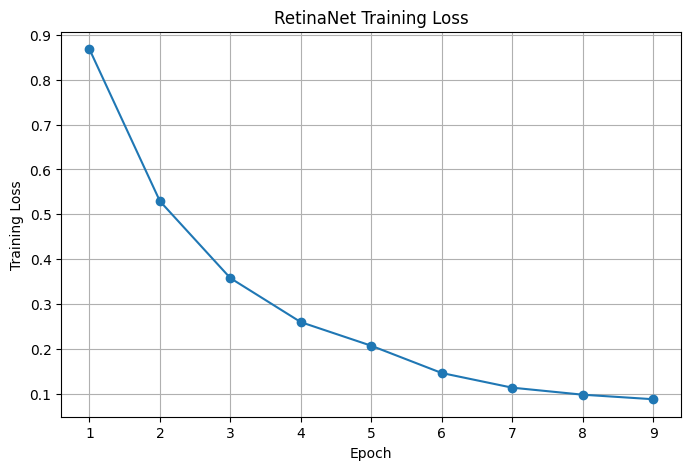

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("RetinaNet Training Loss")
plt.grid()

plt.show()

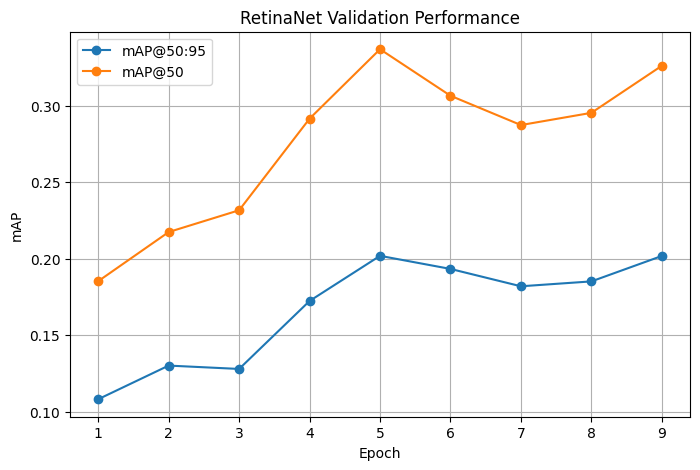

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["val_map"],
    marker="o",
    label="mAP@50:95"
)

plt.plot(
    epochs,
    history["val_map50"],
    marker="o",
    label="mAP@50"
)

plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("RetinaNet Validation Performance")
plt.legend()
plt.grid()

plt.show()

In [ ]:
best_epoch = (
    history["val_map"].index(
        max(history["val_map"])
    ) + 1
)

print("Best epoch:", best_epoch)
print(
    f"Best mAP@50:95: "
    f"{max(history['val_map']):.4f}"
)

print(
    f"mAP@50 at best epoch: "
    f"{history['val_map50'][best_epoch - 1]:.4f}"
)

Best epoch: 5
Best mAP@50:95: 0.2018
mAP@50 at best epoch: 0.3369


In [ ]:
from torchvision.ops import box_iou
import torch
import numpy as np

@torch.no_grad()
def retinanet_yolo_style_pr(
    model,
    data_loader,
    device,
    iou_threshold=0.50
):
    model.eval()

    # Store all model outputs once
    all_predictions = []
    all_targets = []

    for images, targets in data_loader:

        images = [
            image.to(device)
            for image in images
        ]

        predictions = model(images)

        for prediction, target in zip(
            predictions,
            targets
        ):
            all_predictions.append({
                "boxes": prediction["boxes"].cpu(),
                "scores": prediction["scores"].cpu(),
                "labels": prediction["labels"].cpu()
            })

            all_targets.append({
                "boxes": target["boxes"].cpu(),
                "labels": target["labels"].cpu()
            })

    thresholds = np.linspace(
        0.001,
        0.999,
        200
    )

    results = []

    for threshold in thresholds:

        tp = 0
        fp = 0
        fn = 0

        for prediction, target in zip(
            all_predictions,
            all_targets
        ):

            keep = (
                prediction["scores"]
                >= threshold
            )

            pred_boxes = (
                prediction["boxes"][keep]
            )

            pred_scores = (
                prediction["scores"][keep]
            )

            pred_labels = (
                prediction["labels"][keep]
            )

            gt_boxes = target["boxes"]
            gt_labels = target["labels"]

            for class_id in range(1, 6):

                p_mask = (
                    pred_labels == class_id
                )

                g_mask = (
                    gt_labels == class_id
                )

                p_boxes = pred_boxes[p_mask]
                p_scores = pred_scores[p_mask]
                g_boxes = gt_boxes[g_mask]

                if len(g_boxes) == 0:
                    fp += len(p_boxes)
                    continue

                if len(p_boxes) == 0:
                    fn += len(g_boxes)
                    continue

                order = torch.argsort(
                    p_scores,
                    descending=True
                )

                p_boxes = p_boxes[order]

                matched_gt = set()

                for p_box in p_boxes:

                    ious = box_iou(
                        p_box.unsqueeze(0),
                        g_boxes
                    )[0]

                    best_iou, best_idx = (
                        ious.max(0)
                    )

                    best_idx = int(best_idx)

                    if (
                        best_iou >= iou_threshold
                        and
                        best_idx not in matched_gt
                    ):
                        tp += 1
                        matched_gt.add(best_idx)

                    else:
                        fp += 1

                fn += (
                    len(g_boxes)
                    - len(matched_gt)
                )

        precision = (
            tp / (tp + fp)
            if tp + fp > 0
            else 0
        )

        recall = (
            tp / (tp + fn)
            if tp + fn > 0
            else 0
        )

        f1 = (
            2 * precision * recall
            / (precision + recall)
            if precision + recall > 0
            else 0
        )

        results.append({
            "threshold": threshold,
            "precision": precision,
            "recall": recall,
            "f1": f1
        })

    best = max(
        results,
        key=lambda x: x["f1"]
    )

    return best, results

In [ ]:
best_pr, pr_results = (
    retinanet_yolo_style_pr(
        retinanet,
        valid_loader,
        device
    )
)

print(
    f"Best confidence threshold: "
    f"{best_pr['threshold']:.3f}"
)

print(
    f"Precision: "
    f"{best_pr['precision']:.4f}"
)

print(
    f"Recall: "
    f"{best_pr['recall']:.4f}"
)

print(
    f"F1: "
    f"{best_pr['f1']:.4f}"
)

Best confidence threshold: 0.849
Precision: 0.8085
Recall: 0.6129
F1: 0.6972


## 8. Detailed Validation Performance

The best saved RetinaNet checkpoint is reloaded and evaluated on the validation set to obtain:

- overall mAP@50 and mAP@50:95;
- class-specific AP;
- class-specific precision, recall and F1-score; and
- a detection confusion matrix including background false positives and false negatives.

In [ ]:
from pathlib import Path
import torch

# Path to the BEST checkpoint saved during training.
# This is the checkpoint selected using validation mAP@50:95,
# not simply the final epoch.
best_model_path = Path(
    "/content/drive/MyDrive/MMA3001_Project/model_runs/"
    "retinanet_resnet50_v1/best.pt"
)

print("Checkpoint exists:", best_model_path.exists())

# Load the trained weights into the RetinaNet architecture
retinanet.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

# Put model onto GPU and switch off training behaviour
retinanet = retinanet.to(device)
retinanet.eval()

# Use standard maximum of 100 detections per image
retinanet.detections_per_img = 100

print("Best RetinaNet checkpoint loaded successfully.")

Checkpoint exists: True
Best RetinaNet checkpoint loaded successfully.


In [ ]:
@torch.no_grad()
def collect_predictions(model, data_loader, device):
    """
    Run RetinaNet over the full validation dataset once.

    Returns:
        predictions_all:
            List of prediction dictionaries containing
            boxes, scores and predicted labels.

        targets_all:
            List of ground-truth dictionaries containing
            boxes and true labels.
    """

    model.eval()

    predictions_all = []
    targets_all = []

    for images, targets in data_loader:

        # Move images onto GPU
        images_gpu = [
            image.to(device)
            for image in images
        ]

        # RetinaNet inference
        predictions = model(images_gpu)

        # Move everything back to CPU for evaluation
        for prediction, target in zip(
            predictions,
            targets
        ):
            predictions_all.append({
                "boxes": prediction["boxes"].cpu(),
                "scores": prediction["scores"].cpu(),
                "labels": prediction["labels"].cpu()
            })

            targets_all.append({
                "boxes": target["boxes"].cpu(),
                "labels": target["labels"].cpu()
            })

    return predictions_all, targets_all


predictions_all, targets_all = collect_predictions(
    retinanet,
    valid_loader,
    device
)

print(
    "Validation images evaluated:",
    len(predictions_all)
)

Validation images evaluated: 123


In [ ]:
!pip install -q torchmetrics pycocotools
from torchmetrics.detection.mean_ap import MeanAveragePrecision

# -------------------------------------------------------
# Metric 1:
# Standard COCO-style AP averaged from IoU 0.50 to 0.95
# -------------------------------------------------------
metric_5095 = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True
)

# -------------------------------------------------------
# Metric 2:
# AP evaluated specifically at IoU = 0.50
# This allows us to obtain AP@50 for EACH class as well.
# -------------------------------------------------------
metric_50 = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True,
    iou_thresholds=[0.50]
)

metric_5095.update(
    predictions_all,
    targets_all
)

metric_50.update(
    predictions_all,
    targets_all
)

results_5095 = metric_5095.compute()
results_50 = metric_50.compute()

print("Overall RetinaNet Validation Performance")
print("----------------------------------------")
print(
    f"mAP@50:95: "
    f"{results_5095['map'].item():.4f}"
)
print(
    f"mAP@50:    "
    f"{results_5095['map_50'].item():.4f}"
)
print(
    f"mAP@75:    "
    f"{results_5095['map_75'].item():.4f}"
)
print(
    f"mAR@100:   "
    f"{results_5095['mar_100'].item():.4f}"
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 54.7 MB/s eta 0:00:00
Overall RetinaNet Validation Performance
----------------------------------------
mAP@50:95: 0.2018
mAP@50:    0.3369
mAP@75:    0.2141
mAR@100:   0.3204


In [ ]:
import pandas as pd

per_class_results = []

# TorchMetrics returns the class IDs in the same order
# as map_per_class.
for i, class_id_tensor in enumerate(
    results_5095["classes"]
):

    class_id = int(class_id_tensor)

    per_class_results.append({
        "Class": class_names[class_id],

        # Average precision at IoU = 0.50
        "AP@50": float(
            results_50["map_per_class"][i]
        ),

        # Average precision averaged from IoU 0.50–0.95
        "AP@50:95": float(
            results_5095["map_per_class"][i]
        )
    })

per_class_df = pd.DataFrame(
    per_class_results
)

per_class_df

,Class,AP@50,AP@50:95
0,loose-meat,0.472839,0.317340
1,packaging-error,0.167650,0.041485
2,twisted-meat,0.168317,0.084158
3,unsealed,0.875809,0.566225
4,wrinkle,0.000000,0.000000


In [ ]:
from torchvision.ops import box_iou
import torch

CONF_THRESHOLD = 0.849
IOU_THRESHOLD = 0.50

# Five actual defect classes
NUM_CLASSES = 5

# Final index represents background
BACKGROUND = NUM_CLASSES

# Matrix:
# rows    = predicted class
# columns = true class
#
# 0 loose-meat
# 1 packaging-error
# 2 twisted-meat
# 3 unsealed
# 4 wrinkle
# 5 background
confusion_matrix = torch.zeros(
    (NUM_CLASSES + 1, NUM_CLASSES + 1),
    dtype=torch.int64
)


for prediction, target in zip(
    predictions_all,
    targets_all
):

    # -------------------------------
    # Extract predictions
    # -------------------------------
    pred_boxes = prediction["boxes"]
    pred_scores = prediction["scores"]
    pred_labels = prediction["labels"]

    # Only retain detections above the selected
    # confidence operating threshold.
    keep = pred_scores >= CONF_THRESHOLD

    pred_boxes = pred_boxes[keep]
    pred_scores = pred_scores[keep]
    pred_labels = pred_labels[keep]

    # -------------------------------
    # Extract ground truth
    # -------------------------------
    gt_boxes = target["boxes"]
    gt_labels = target["labels"]

    # Process highest-confidence detections first.
    order = torch.argsort(
        pred_scores,
        descending=True
    )

    pred_boxes = pred_boxes[order]
    pred_labels = pred_labels[order]

    # Keep track of GT boxes that have already
    # been assigned to a prediction.
    matched_gt = set()

    # -------------------------------
    # Match predictions to ground truth
    # -------------------------------
    for pred_box, pred_label in zip(
        pred_boxes,
        pred_labels
    ):

        # Torchvision class IDs are 1–5.
        # Matrix indices are 0–4.
        pred_index = int(pred_label) - 1

        # If there are no labelled defects in
        # this image, every prediction is a FP.
        if len(gt_boxes) == 0:

            confusion_matrix[
                pred_index,
                BACKGROUND
            ] += 1

            continue

        # IoU between this prediction and
        # every true bounding box
        ious = box_iou(
            pred_box.unsqueeze(0),
            gt_boxes
        )[0]

        # Prevent an already-matched GT box from
        # being matched to a second prediction.
        for matched_index in matched_gt:
            ious[matched_index] = -1

        best_iou, best_gt_index = ious.max(0)

        best_gt_index = int(best_gt_index)

        if best_iou >= IOU_THRESHOLD:

            true_label = int(
                gt_labels[best_gt_index]
            )

            true_index = true_label - 1

            # Correct class -> diagonal
            # Wrong class   -> off diagonal
            confusion_matrix[
                pred_index,
                true_index
            ] += 1

            matched_gt.add(
                best_gt_index
            )

        else:
            # Detection does not sufficiently overlap
            # any ground-truth object -> false positive
            confusion_matrix[
                pred_index,
                BACKGROUND
            ] += 1

    # -------------------------------
    # Ground truths that were never matched
    # are false negatives.
    # -------------------------------
    for gt_index, gt_label in enumerate(
        gt_labels
    ):

        if gt_index not in matched_gt:

            true_index = int(gt_label) - 1

            confusion_matrix[
                BACKGROUND,
                true_index
            ] += 1

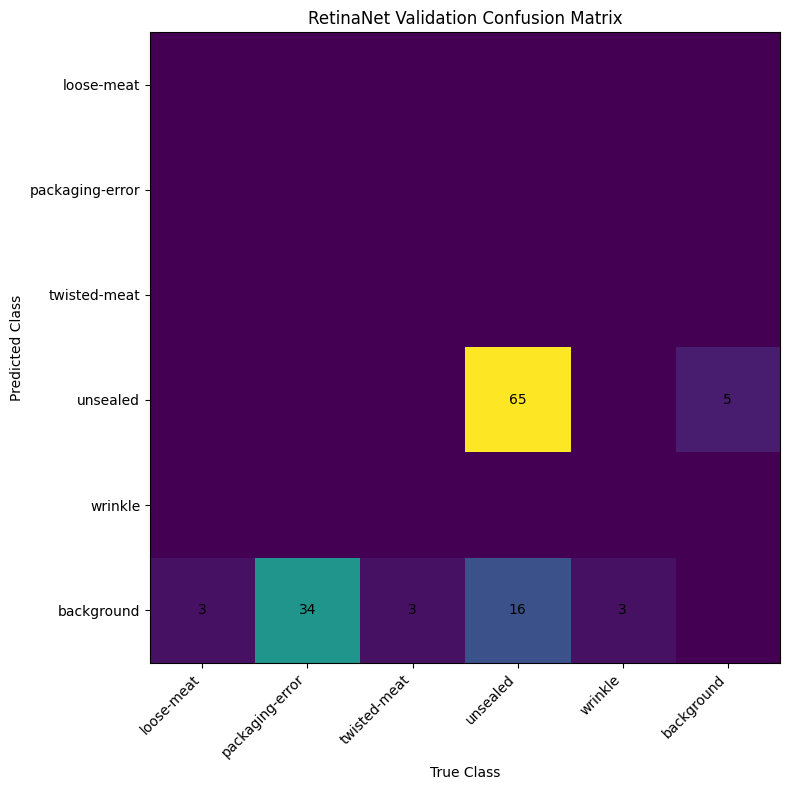

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

matrix_labels = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle",
    "background"
]

cm = confusion_matrix.numpy()

fig, ax = plt.subplots(
    figsize=(10, 8)
)

image = ax.imshow(cm)

# Axis labels
ax.set_xticks(
    np.arange(len(matrix_labels))
)

ax.set_yticks(
    np.arange(len(matrix_labels))
)

ax.set_xticklabels(
    matrix_labels,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(
    matrix_labels
)

ax.set_xlabel("True Class")
ax.set_ylabel("Predicted Class")

ax.set_title(
    "RetinaNet Validation Confusion Matrix"
)

# Print count inside each matrix cell
for row in range(cm.shape[0]):
    for col in range(cm.shape[1]):

        value = cm[row, col]

        if value > 0:
            ax.text(
                col,
                row,
                str(value),
                ha="center",
                va="center"
            )

plt.tight_layout()
plt.show()

In [ ]:
class_metric_rows = []

for class_index in range(NUM_CLASSES):

    class_name = matrix_labels[
        class_index
    ]

    # Correct detections for this class
    true_positive = int(
        confusion_matrix[
            class_index,
            class_index
        ]
    )

    # Everything predicted as this class
    # that was actually something else/background
    false_positive = int(
        confusion_matrix[
            class_index,
            :
        ].sum()
        - true_positive
    )

    # Everything truly belonging to this class
    # that was predicted incorrectly or missed
    false_negative = int(
        confusion_matrix[
            :,
            class_index
        ].sum()
        - true_positive
    )

    precision = (
        true_positive
        / (true_positive + false_positive)
        if true_positive + false_positive > 0
        else 0.0
    )

    recall = (
        true_positive
        / (true_positive + false_negative)
        if true_positive + false_negative > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if precision + recall > 0
        else 0.0
    )

    class_metric_rows.append({
        "Class": class_name,
        "TP": true_positive,
        "FP": false_positive,
        "FN": false_negative,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })


class_metrics_df = pd.DataFrame(
    class_metric_rows
)

class_metrics_df

,Class,TP,FP,FN,Precision,Recall,F1
0,loose-meat,0,0,3,0.000000,0.000000,0.000000
1,packaging-error,0,0,34,0.000000,0.000000,0.000000
2,twisted-meat,0,0,3,0.000000,0.000000,0.000000
3,unsealed,65,5,16,0.928571,0.802469,0.860927
4,wrinkle,0,0,3,0.000000,0.000000,0.000000


In [ ]:
full_class_results = pd.merge(
    per_class_df,
    class_metrics_df,
    on="Class"
)

full_class_results

,Class,AP@50,AP@50:95,TP,FP,FN,Precision,Recall,F1
0,loose-meat,0.472839,0.317340,0,0,3,0.000000,0.000000,0.000000
1,packaging-error,0.167650,0.041485,0,0,34,0.000000,0.000000,0.000000
2,twisted-meat,0.168317,0.084158,0,0,3,0.000000,0.000000,0.000000
3,unsealed,0.875809,0.566225,65,5,16,0.928571,0.802469,0.860927
4,wrinkle,0.000000,0.000000,0,0,3,0.000000,0.000000,0.000000


OVERALL CONFIDENCE THRESHOLD COMPARISON


,Threshold,TP,FP,FN,Precision,Recall,F1
0,0.100,96,501,28,0.1608,0.7742,0.2663
1,0.250,86,71,38,0.5478,0.6935,0.6121
2,0.500,74,18,50,0.8043,0.5968,0.6852
3,0.700,70,11,54,0.8642,0.5645,0.6829
4,0.849,65,5,59,0.9286,0.5242,0.6701



CORRECT DETECTIONS BY CLASS


Class,loose-meat,packaging-error,twisted-meat,unsealed,wrinkle
Threshold,,,,,
0.100,3,17,1,75,0
0.250,0,11,1,74,0
0.500,0,3,0,71,0
0.700,0,0,0,70,0
0.849,0,0,0,65,0



PER-CLASS RECALL


Class,loose-meat,packaging-error,twisted-meat,unsealed,wrinkle
Threshold,,,,,
0.100,1.0,0.5000,0.3333,0.9259,0.0
0.250,0.0,0.3235,0.3333,0.9136,0.0
0.500,0.0,0.0882,0.0000,0.8765,0.0
0.700,0.0,0.0000,0.0000,0.8642,0.0
0.849,0.0,0.0000,0.0000,0.8025,0.0


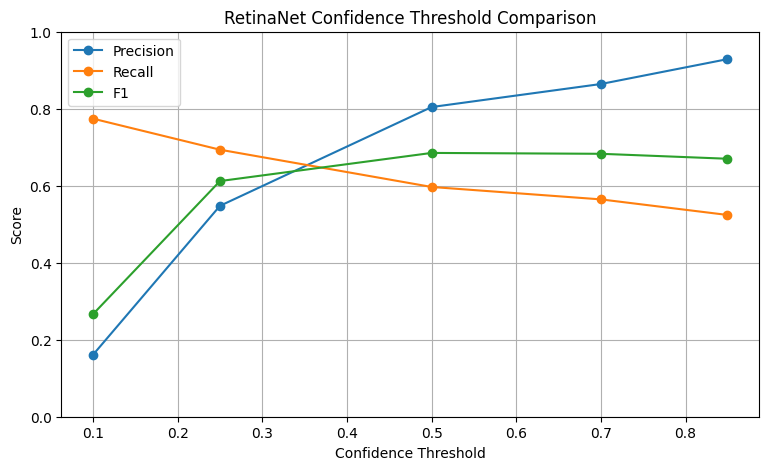

Best tested threshold: 0.500
Precision: 0.8043
Recall: 0.5968
F1: 0.6852


In [ ]:

import torch
import pandas as pd
import matplotlib.pyplot as plt
from torchvision.ops import box_iou

# Confidence thresholds to compare
THRESHOLDS = [0.10, 0.25, 0.50, 0.70, 0.849]
IOU_THRESHOLD = 0.50

CLASS_NAMES = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

overall_results = []
class_results = []

# Use the saved validation predictions from Cell 35
for threshold in THRESHOLDS:

    total_tp = 0
    total_fp = 0
    total_fn = 0

    for class_id, class_name in enumerate(CLASS_NAMES, start=1):

        tp = 0
        fp = 0
        fn = 0
        accepted_predictions = 0

        for prediction, target in zip(
            predictions_all, targets_all
        ):

            # Filter predictions by confidence and class
            keep = (
                (prediction["scores"] >= threshold)
                & (prediction["labels"] == class_id)
            )

            pred_boxes = prediction["boxes"][keep]
            pred_scores = prediction["scores"][keep]

            gt_boxes = target["boxes"][
                target["labels"] == class_id
            ]

            accepted_predictions += len(pred_boxes)

            # Sort predictions by confidence
            order = torch.argsort(
                pred_scores, descending=True
            )

            pred_boxes = pred_boxes[order]

            matched_gt = set()

            for pred_box in pred_boxes:

                if len(gt_boxes) == 0:
                    fp += 1
                    continue

                ious = box_iou(
                    pred_box.unsqueeze(0), gt_boxes
                )[0]

                # Exclude previously matched objects
                for idx in matched_gt:
                    ious[idx] = -1

                best_iou, best_idx = ious.max(0)
                best_idx = int(best_idx)

                if best_iou >= IOU_THRESHOLD:
                    tp += 1
                    matched_gt.add(best_idx)
                else:
                    fp += 1

            fn += len(gt_boxes) - len(matched_gt)

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        class_results.append({
            "Threshold": threshold,
            "Class": class_name,
            "Predictions": accepted_predictions,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

        total_tp += tp
        total_fp += fp
        total_fn += fn

    overall_precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp else 0
    )
    overall_recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn else 0
    )
    overall_f1 = (
        2 * overall_precision * overall_recall
        / (overall_precision + overall_recall)
        if overall_precision + overall_recall else 0
    )

    overall_results.append({
        "Threshold": threshold,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "Precision": overall_precision,
        "Recall": overall_recall,
        "F1": overall_f1
    })

# Convert to DataFrames
overall_df = pd.DataFrame(overall_results)
class_df = pd.DataFrame(class_results)

print("OVERALL CONFIDENCE THRESHOLD COMPARISON")
display(overall_df.round(4))

print("\nCORRECT DETECTIONS BY CLASS")
tp_table = class_df.pivot(
    index="Threshold",
    columns="Class",
    values="TP"
)

display(tp_table)

print("\nPER-CLASS RECALL")
recall_table = class_df.pivot(
    index="Threshold",
    columns="Class",
    values="Recall"
)

display(recall_table.round(4))

# Plot performance against threshold
plt.figure(figsize=(9, 5))

plt.plot(
    overall_df["Threshold"],
    overall_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    overall_df["Threshold"],
    overall_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    overall_df["Threshold"],
    overall_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Score")
plt.title("RetinaNet Confidence Threshold Comparison")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()

# Find best threshold among those tested
best_row = overall_df.loc[
    overall_df["F1"].idxmax()
]

print(
    f"Best tested threshold: {best_row['Threshold']:.3f}"
)
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall: {best_row['Recall']:.4f}")
print(f"F1: {best_row['F1']:.4f}")


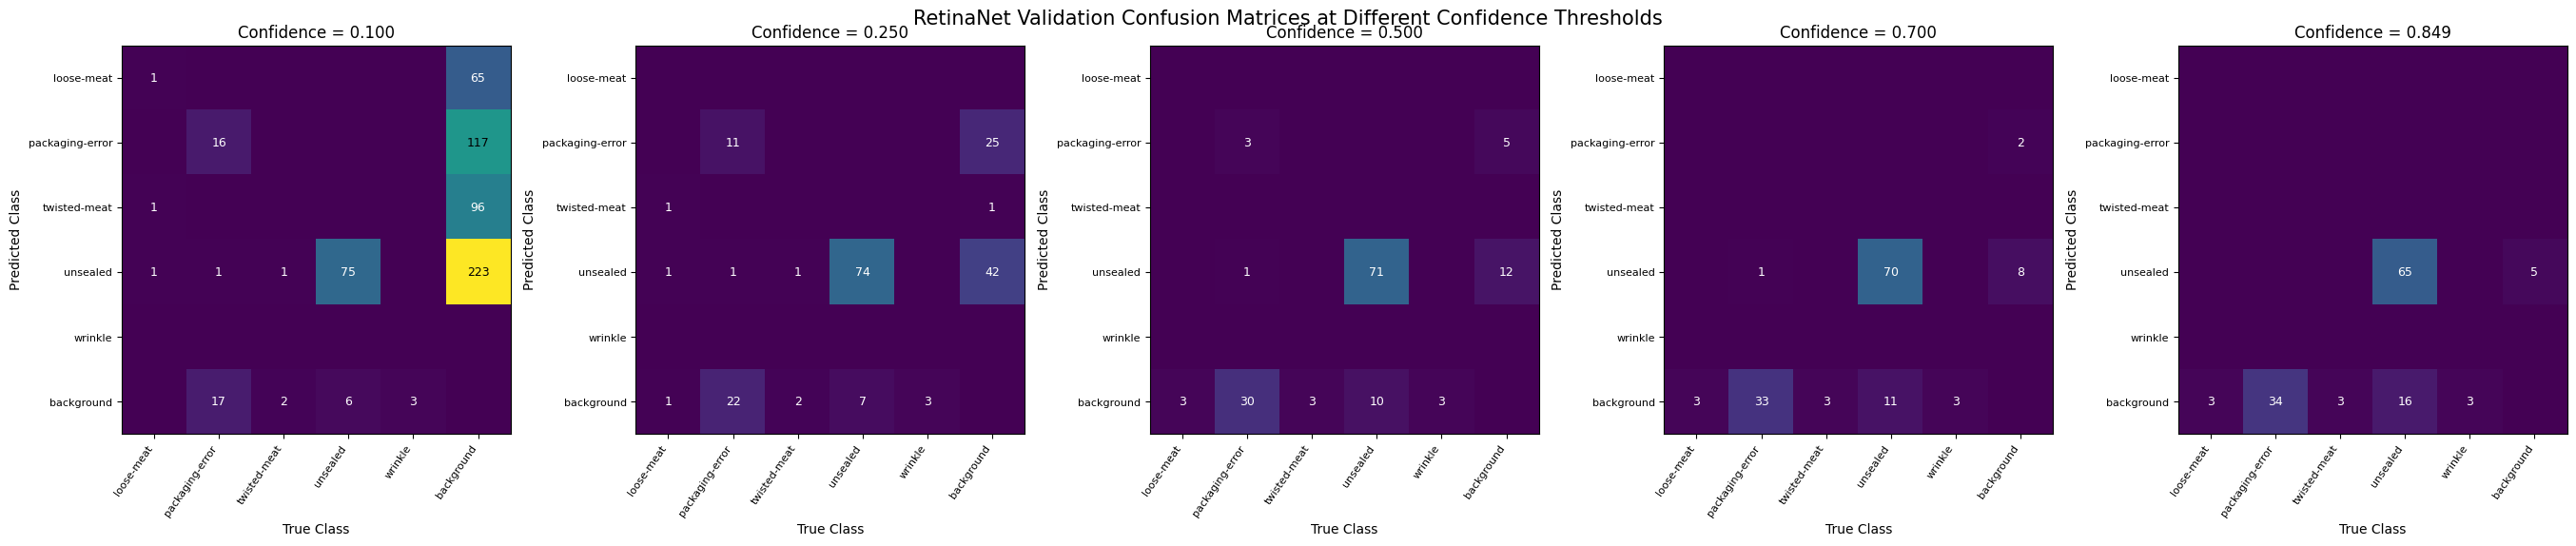


CORRECT DETECTIONS BY CONFIDENCE THRESHOLD
---------------------------------------------------------------------------
Threshold   loose-meat        packaging-error   twisted-meat      unsealed          wrinkle           
0.100       1                 16                0                 75                0                 
0.250       0                 11                0                 74                0                 
0.500       0                 3                 0                 71                0                 
0.700       0                 0                 0                 70                0                 
0.849       0                 0                 0                 65                0                 


In [ ]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from torchvision.ops import box_iou

THRESHOLDS = [0.10, 0.25, 0.50, 0.70, 0.849]
IOU_THRESHOLD = 0.50

matrix_labels = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle",
    "background"
]

NUM_CLASSES = 5
BACKGROUND = 5


def generate_confusion_matrix(conf_threshold):

    cm = torch.zeros(
        (NUM_CLASSES + 1, NUM_CLASSES + 1),
        dtype=torch.int64
    )

    for prediction, target in zip(
        predictions_all, targets_all
    ):

        pred_boxes = prediction["boxes"]
        pred_scores = prediction["scores"]
        pred_labels = prediction["labels"]

        # Apply confidence threshold
        keep = pred_scores >= conf_threshold

        pred_boxes = pred_boxes[keep]
        pred_scores = pred_scores[keep]
        pred_labels = pred_labels[keep]

        gt_boxes = target["boxes"]
        gt_labels = target["labels"]

        # Sort highest confidence first
        order = torch.argsort(
            pred_scores, descending=True
        )

        pred_boxes = pred_boxes[order]
        pred_labels = pred_labels[order]

        matched_gt = set()

        for pred_box, pred_label in zip(
            pred_boxes, pred_labels
        ):

            pred_index = int(pred_label) - 1

            if len(gt_boxes) == 0:
                cm[pred_index, BACKGROUND] += 1
                continue

            ious = box_iou(
                pred_box.unsqueeze(0), gt_boxes
            )[0]

            for matched_index in matched_gt:
                ious[matched_index] = -1

            best_iou, best_gt_index = ious.max(0)
            best_gt_index = int(best_gt_index)

            if best_iou >= IOU_THRESHOLD:

                true_index = (
                    int(gt_labels[best_gt_index]) - 1
                )

                cm[pred_index, true_index] += 1
                matched_gt.add(best_gt_index)

            else:
                cm[pred_index, BACKGROUND] += 1

        # Count missed ground-truth defects
        for gt_index, gt_label in enumerate(gt_labels):

            if gt_index not in matched_gt:
                true_index = int(gt_label) - 1
                cm[BACKGROUND, true_index] += 1

    return cm.numpy()


# Generate all matrices
matrices = [
    generate_confusion_matrix(t)
    for t in THRESHOLDS
]

# Plot all five side by side
fig, axes = plt.subplots(
    1, len(THRESHOLDS),
    figsize=(27, 5.5),
    constrained_layout=True
)

max_value = max(cm.max() for cm in matrices)

for ax, threshold, cm in zip(
    axes, THRESHOLDS, matrices
):

    ax.imshow(
        cm,
        cmap="viridis",
        vmin=0,
        vmax=max_value
    )

    ax.set_title(
        f"Confidence = {threshold:.3f}",
        fontsize=12
    )

    ax.set_xticks(range(len(matrix_labels)))
    ax.set_yticks(range(len(matrix_labels)))

    ax.set_xticklabels(
        matrix_labels,
        rotation=55,
        ha="right",
        fontsize=8
    )

    ax.set_yticklabels(
        matrix_labels,
        fontsize=8
    )

    ax.set_xlabel("True Class")
    ax.set_ylabel("Predicted Class")

    for row in range(cm.shape[0]):
        for col in range(cm.shape[1]):

            value = cm[row, col]

            if value > 0:
                ax.text(
                    col, row,
                    str(value),
                    ha="center",
                    va="center",
                    fontsize=9,
                    color=(
                        "black"
                        if value > max_value / 2
                        else "white"
                    )
                )

plt.suptitle(
    "RetinaNet Validation Confusion Matrices "
    "at Different Confidence Thresholds",
    fontsize=15
)

plt.show()


# Additional summary: Correct detections per class
print("\nCORRECT DETECTIONS BY CONFIDENCE THRESHOLD")
print("-" * 75)

print(
    f"{'Threshold':<12}"
    + "".join(f"{name:<18}" for name in matrix_labels[:5])
)

for threshold, cm in zip(THRESHOLDS, matrices):
    print(
        f"{threshold:<12.3f}"
        + "".join(
            f"{cm[i, i]:<18}"
            for i in range(NUM_CLASSES)
        )
    )
